[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nattaponm/Teach_stormTracks_KKN_May2024_HID_doppler/blob/main/notebooks/03_tdating_tracks_dt15_10_5.ipynb)


# บทที่ 03 — ติดตามพายุด้วย T-DaTing: ทดลอง Δt = 15, 10 และ 5 นาที

เรดาร์ KKN ให้ภาพทุก 15 นาที พายุเคลื่อนที่ 20–40 km/h จึงเลื่อนไป 5–10 km ระหว่างภาพ ซึ่งเทียบได้กับขนาดของเซลล์เอง การจับคู่ "ลูกเดิม" ข้ามเวลาจึงผิดพลาดได้ บทนี้ทดลองสร้างภาพ 10 และ 5 นาทีด้วย advection interpolation แล้วดูว่าเส้นทางที่ได้ต่างกันอย่างไร — ต่อยอดจาก repo `Teach_Tdating_strom_tracks_HID_CloudProperties` ซึ่งทำวันเดียว มาเป็นทั้งเดือน

### วัตถุประสงค์การเรียนรู้
1. อธิบายขั้นตอนของ T-DaTing (ระบุเซลล์ → คาดตำแหน่ง → จับคู่) และความหมายของพารามิเตอร์หลัก
2. สร้างภาพระหว่างเวลาด้วย advection interpolation แบบ linZ และอธิบายว่าทำไมภาพสังเคราะห์ใช้ "ติดตาม" ได้แต่ไม่ใช้ "วัดความเข้ม"
3. เปรียบเทียบจำนวน อายุ ความเร็ว และความยาวเส้นทางระหว่าง Δt ทั้งเดือน
4. จับคู่เส้นทางข้ามความละเอียดด้วย IoU ของ footprint
5. อธิบายว่าทำไมต้องติดตามเป็น "เหตุการณ์พายุ" (episode) แทนทีละวัน และความหมายของเส้นทางที่ถูกตัด (censored)

In [1]:
# @title ⚙️ เตรียมสภาพแวดล้อม (รันก่อนเสมอ)
import os, sys, subprocess
REPO = "Teach_stormTracks_KKN_May2024_HID_doppler"
if "google.colab" in sys.modules:
    if not os.path.isdir(f"/content/{REPO}"):
        subprocess.run(["git", "clone", "-q", "--depth", "1", f"https://github.com/nattaponm/{REPO}.git", f"/content/{REPO}"], check=True)
    else:
        subprocess.run(["git", "-C", f"/content/{REPO}", "pull", "-q"])
    os.chdir(f"/content/{REPO}")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pysteps==1.21.5", "opencv-python-headless"], check=True)
elif os.path.basename(os.getcwd()) in ("notebooks", "prep"):
    os.chdir("..")
sys.path.insert(0, os.getcwd())
print("โฟลเดอร์ทำงาน:", os.getcwd(), "| CPU", os.cpu_count(), "core")

โฟลเดอร์ทำงาน: /content/Teach_stormTracks_KKN_May2024_HID_doppler | CPU 2 core


In [2]:
import warnings
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats, ndimage
warnings.filterwarnings("ignore")

from utils.config import load_settings, repo_path
from utils import maps as M, geo as G, data as D, analysis as A, track_tools as tt
s = load_settings()
M.setup_style()
pd.set_option("display.width", 200, "display.max_columns", 30)
DEM = G.load_dem(s)                                   # (array, extent) — สร้างจาก Copernicus ครั้งแรกถ้ายังไม่มี
idx = D.day_index()
KEY_DAYS = list(idx.loc[idx["in_repo"], "day"]) if len(idx) else [pd.Timestamp("2024-05-03")]
KEY = KEY_DAYS[0]                                     # วันหลักที่มีกริดใน repo (เปลี่ยนเป็นวันอื่นได้ จะดาวน์โหลดจาก Zenodo)
print("วันหลักใน repo:", [f"{d:%d %b}" for d in KEY_DAYS], "| ใช้วัน:", f"{KEY:%d %b %Y}")

try:
    from pysteps.tracking import tdating  # noqa: F401
    HAS_PYSTEPS = True
except Exception:
    HAS_PYSTEPS = False
print("pysteps:", HAS_PYSTEPS, "| พารามิเตอร์ T-DaTing:", tt.PARAMS, tt.TRACK_KW)

วันหลักใน repo: ['03 May', '05 May', '06 May', '22 May'] | ใช้วัน: 03 May 2024
Pysteps configuration file found at: /usr/local/lib/python3.13/dist-packages/pysteps/pystepsrc

pysteps: True | พารามิเตอร์ T-DaTing: {'minref': 33, 'maxref': 45, 'mindiff': 5, 'minsize': 15, 'minmax': 40, 'mindis': 8} {'mintrack': 2, 'match_frac': 0.25}


## 1. T-DaTing ทำงานอย่างไร

**T-DaTing** (Thunderstorm Detection and Tracking; Feldmann et al. 2021) ใน pysteps:

1. **ระบุเซลล์:** pixel ที่ $Z \ge$ `minref` (33 dBZ) แยกเป็นเซลล์ด้วย watershed เมื่อสองยอดต่างจากจุดต่ำระหว่างกันอย่างน้อย `mindiff` (5 dB) เซลล์ต้องมีขนาด ≥ `minsize` (15 km²) และมีค่าสูงสุด ≥ `minmax` (40 dBZ) ค่าที่เกิน `maxref` (45 dBZ) ถูกตัดก่อน watershed เพื่อไม่ให้แกนแรงแตกย่อยเกินไป
2. **คาดตำแหน่ง:** เลื่อนเซลล์เวลา $t-1$ ไปตามความเร็วที่ประมาณได้
3. **จับคู่:** เซลล์ที่ $t$ ซึ่งซ้อนทับเซลล์ที่เลื่อนแล้วมากพอ (`match_frac` = 0.25) ถือเป็นลูกเดียวกัน ส่วน `mindis` (8 km) จำกัดระยะของการจับคู่

**ภาพสังเคราะห์ (advection interpolation)** ระหว่างภาพจริง $Z_a$ ($t_0$) กับ $Z_b$ ($t_0+\Delta t$) ที่สัดส่วนเวลา $w$:

$$Z(t_0 + w\Delta t) = 10\log_{10}\!\Big[(1-w)\,10^{Z_a'(w)/10} + w\,10^{Z_b'(w)/10}\Big]$$

โดย $Z_a'$ คือ $Z_a$ ที่เลื่อนไปข้างหน้า $w$ ช่วง และ $Z_b'$ คือ $Z_b$ ที่เลื่อนถอยหลัง $1-w$ ช่วง ตามสนามการเคลื่อนที่ Lucas–Kanade ผลคือภาพ **เรียบ** แต่ **แกน ≥ 45 dBZ อ่อนลง** (ถูกเฉลี่ย) — ค่า HID/dual-pol/Doppler ทั้งหมดในบทต่อไปจึงดึงจากภาพจริงเท่านั้น

## 2. ทดลองสด: ติดตาม 2 ชั่วโมงรอบช่วงพีคของวันหลัก (15 vs 5 นาที)

In [3]:
Z, meta = D.load_cappi(KEY)
times = pd.to_datetime(meta["timestamps"])
area = np.array([np.nansum(z >= 35) for z in Z]); it = int(np.nanargmax(area))
i0, i1 = max(0, it - 4), min(len(Z) - 1, it + 4)
assert meta["available"][i0:i1 + 1].all(), "ช่วงนี้มีข้อมูลขาด — เลือกช่วงอื่น"
Zs, ts = Z[i0:i1 + 1], list(times[i0:i1 + 1].to_pydatetime())
print(f"ช่วง {ts[0]:%H:%M}–{ts[-1]:%H:%M} UTC ({len(ts)} ภาพจริง)")
if HAS_PYSTEPS:
    tr15 = tt.run_tdating(Zs, ts)
    Z5, t5, obs5 = tt.advect_interpolate(Zs, ts, n_sub=3, method="linZ")
    tr5 = tt.run_tdating(Z5, t5)
    a45 = [np.nansum(z >= 45) for z in Z5]
    print(f"15 นาที: {len(tr15)} เส้นทาง | 5 นาที: {len(tr5)} เส้นทาง จาก {len(t5)} ภาพ ({(~obs5).sum()} ภาพสังเคราะห์)")
    print(f"พื้นที่ ≥ 45 dBZ มัธยฐาน: ภาพจริง {np.median(np.array(a45)[obs5]):.0f} km², ภาพสังเคราะห์ {np.median(np.array(a45)[~obs5]):.0f} km²")
else:
    print("ไม่มี pysteps — ข้ามการทดลองสด ใช้ผลที่คำนวณไว้แล้วในหัวข้อถัดไป")

ช่วง 09:00–11:00 UTC (9 ภาพจริง)
15 นาที: 25 เส้นทาง | 5 นาที: 54 เส้นทาง จาก 25 ภาพ (16 ภาพสังเคราะห์)
พื้นที่ ≥ 45 dBZ มัธยฐาน: ภาพจริง 121 km², ภาพสังเคราะห์ 48 km²


บันทึกรูป → /content/Teach_stormTracks_KKN_May2024_HID_doppler/figures/nb03_live_tracks.png / .pdf


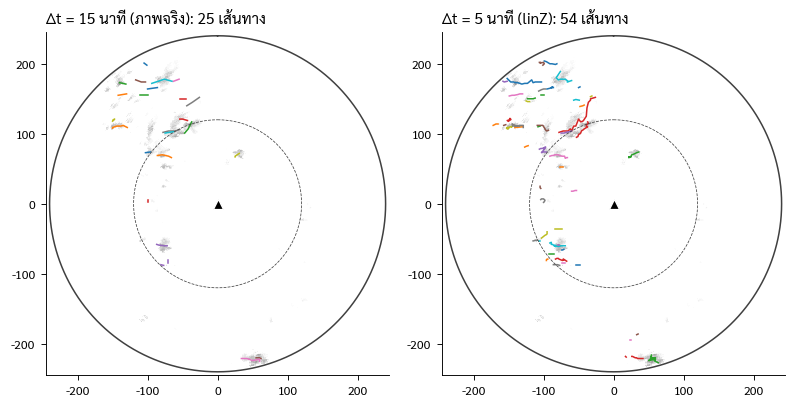

In [4]:
if HAS_PYSTEPS:
    fig, axs = plt.subplots(1, 2, figsize=(7.2, 3.6), layout="constrained")
    for ax, (tr, ttl) in zip(axs, [(tr15, "Δt = 15 นาที (ภาพจริง)"), (tr5, "Δt = 5 นาที (linZ)")]):
        A.show_grid(ax, np.where(Zs[it - i0] >= 20, Zs[it - i0], np.nan), meta, cmap="Greys", vmin=20, vmax=60, alpha=0.5)
        for k, c in enumerate(tr):
            ax.plot(meta["x"][c["cen_x"].round().astype(int)] / 1e3, meta["y"][c["cen_y"].round().astype(int)] / 1e3,   # cen_x/cen_y = index คอลัมน์/แถว
                    "-", lw=1, color=plt.get_cmap("tab10")(k % 10))
        M.add_range_rings(ax, s, rings_km=[120, 240], label=False, name=False)
        ax.set_xlim(-245, 245); ax.set_ylim(-245, 245); ax.set_aspect("equal"); ax.set_title(f"{ttl}: {len(tr)} เส้นทาง", loc="left")
    M.savefig(fig, "nb03_live_tracks")
    plt.show()

## 3. ผลทั้งเดือน (คำนวณไว้แล้วใน prep/P3)

ไฟล์เรดาร์แยกเป็นรายวัน (00:00–23:45 UTC) แต่พายุไม่รู้จักเที่ยงคืน ถ้าติดตามทีละวัน พายุที่ยังอยู่ตอน **00 UTC = 07:00 น.** จะถูกหั่นเป็นสองเส้น (อายุสั้นลง จำนวนเกินจริง เกิด "จุดกำเนิดปลอม" ตอน 07:00 น.) P3 จึงต่อข้อมูลทั้งเดือนเป็นอนุกรมเดียว แล้วแบ่งเป็น **เหตุการณ์พายุ (episode)** เฉพาะที่ **ช่วงสงบ** (พื้นที่ ≥ 35 dBZ < 20 km² ติดกัน ≥ 1 ชม.) หรือ **ข้อมูลขาด** แล้วติดตามทีละเหตุการณ์ — ตรงช่วงสงบไม่มีพายุให้ตัด เส้นทางจึงต่อเนื่องข้ามวันได้

ป้ายกำกับในตารางเส้นทาง: `uid` = `E###-####` (เหตุการณ์-ลำดับ), `day` = วันที่ UTC ของจุดเริ่ม, `day_local` = วันที่เวลาไทย, `crosses_00utc` = คร่อมเที่ยงคืน UTC และ **censored** = เริ่ม/จบที่ขอบเหตุการณ์ที่ติดกับข้อมูลขาดหรือขอบเดือน (อายุจริงอาจยาวกว่าที่วัดได้)

In [5]:
summ = D.table("tracking_summary.csv"); EPI = D.table("episodes.csv")
print(f"เหตุการณ์พายุ {len(EPI)} ครั้ง | ยาวมัธยฐาน {EPI['hours'].median():.1f} ชม. | ยาวสุด {EPI['hours'].max():.1f} ชม. | "
      f"คร่อม 00 UTC {EPI['crosses_00utc'].sum()} ครั้ง")
summ

เหตุการณ์พายุ 39 ครั้ง | ยาวมัธยฐาน 12.2 ชม. | ยาวสุด 64.0 ชม. | คร่อม 00 UTC 14 ครั้ง


,tag,episodes,days,tracks,life>=30min,life>=60min,crosses_00utc,censored,max_life_min
0,15min,33,30,4423,2325,688,26,4,270.0
1,10min_linZ,33,30,5097,2298,817,23,4,280.0
2,05min_linZ,33,30,7074,2422,806,29,5,365.0


บันทึกรูป → /content/Teach_stormTracks_KKN_May2024_HID_doppler/figures/nb03_track_properties_by_dt.png / .pdf


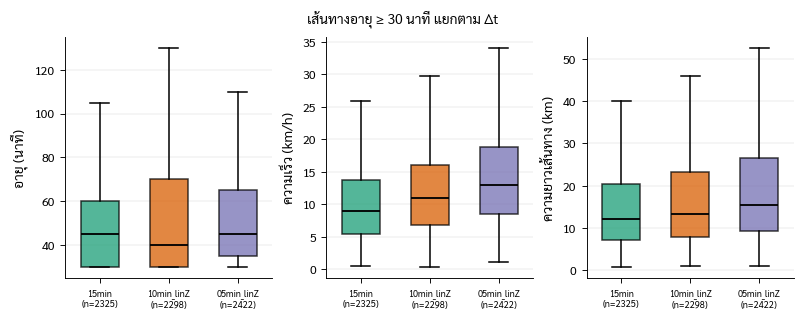

In [6]:
TAGS = ["15min", "10min_linZ", "05min_linZ"]
TT = pd.concat([A.month_tracks(t, min_life=0).assign(tag=t) for t in TAGS], ignore_index=True)
TT["tag"] = pd.Categorical(TT["tag"], TAGS, ordered=True)
long_ = TT[TT["lifetime_min"] >= 30]
fig, axs = plt.subplots(1, 3, figsize=(7.2, 2.8), layout="constrained")
cols = ["#1b9e77", "#d95f02", "#7570b3"]
for ax, (v, lab) in zip(axs, [("lifetime_min", "อายุ (นาที)"), ("speed_kmh", "ความเร็ว (km/h)"), ("path_km", "ความยาวเส้นทาง (km)")]):
    tt.boxplot_groups(ax, long_, v, "tag", order=TAGS, colors=cols, ylabel=lab, points=False)
    ax.tick_params(axis="x", labelsize=6)
fig.suptitle("เส้นทางอายุ ≥ 30 นาที แยกตาม Δt", fontsize=9)
M.savefig(fig, "nb03_track_properties_by_dt")
plt.show()

**อ่านผล:** Δt สั้นลงมักได้ **เส้นทางมากขึ้นและยาวขึ้น** เพราะการเคลื่อนที่ระหว่างภาพเล็กลง การจับคู่ด้วยการซ้อนทับจึงสำเร็จบ่อยขึ้น แต่ภาพสังเคราะห์อาจ "เชื่อม" เซลล์ที่ไม่ใช่ลูกเดียวกันได้ด้วย คำถามคือเส้นทางที่เพิ่มมาเป็นของจริงหรือไม่ — หัวข้อถัดไปตอบด้วยการจับคู่ footprint

## 4. จับคู่เส้นทางข้าม Δt ด้วย IoU ของ footprint

footprint = ชุด pixel ทั้งหมดที่เส้นทางเคยกวาดผ่าน

$$\text{IoU}(A,B) = \frac{|A\cap B|}{|A\cup B|}$$

เส้นทาง 15 นาทีหนึ่งเส้นจับคู่กับเส้นทาง 5 นาทีที่ IoU สูงสุด (≥ 0.1)

In [7]:
lab15, t15_, _ = D.load_labels(KEY, "15min")
lab05, t05_, _ = D.load_labels(KEY, "05min_linZ")
fp15, fp05 = tt.footprint_masks(lab15), tt.footprint_masks(lab05)
m = tt.match_tracks(fp15, fp05, min_iou=0.1)
T15k = A.month_tracks("15min", 0).set_index("track_id")      # track_id ไม่ซ้ำทั้งเดือน
m = m.join(T15k[["lifetime_min"]])
print(f"{KEY:%d %b}: เส้นทาง 15 นาที {len(m)} เส้น จับคู่ได้ {m['match'].notna().sum()} ({100 * m['match'].notna().mean():.0f}%) | IoU มัธยฐาน {m['iou'].median():.2f}")
print(m.groupby(pd.cut(m["lifetime_min"], [0, 30, 60, 1e4], right=False), observed=True)["iou"].median().rename("IoU มัธยฐานตามอายุ").to_string())

03 May: เส้นทาง 15 นาที 165 เส้น จับคู่ได้ 162 (98%) | IoU มัธยฐาน 0.51
lifetime_min
[0.0, 30.0)        0.445727
[30.0, 60.0)       0.500000
[60.0, 10000.0)    0.550907


## 5. แผนที่เส้นทางของวันหลัก 3 ความละเอียด

บันทึกรูป → /content/Teach_stormTracks_KKN_May2024_HID_doppler/figures/nb03_tracks_three_dt.png / .pdf


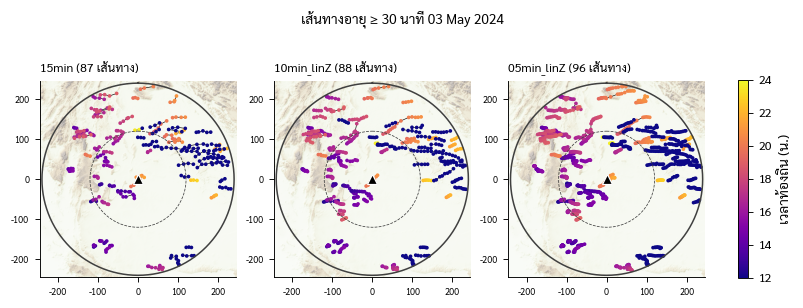

In [8]:
CC = {t: A.month_cells(t) for t in TAGS}
fig, axs = plt.subplots(1, 3, figsize=(7.2, 2.9), layout="constrained")
for ax, t in zip(axs, TAGS):
    C = CC[t]; C = C[C["day"] == KEY]                         # เซลล์ ณ เวลาในวันหลัก
    life = A.month_tracks(t, 0).set_index("uid")["lifetime_min"].reindex(C["uid"].unique())   # อายุของทั้งเส้น (อาจคร่อมวัน)
    M.add_hillshade(ax, *DEM, alpha=0.5)
    for uid, g in C[C["uid"].isin(life.index[life >= 30])].groupby("uid"):
        g = g.sort_values("time")
        sc = ax.scatter(g["cx"] / 1e3, g["cy"] / 1e3, c=(g["time"].dt.hour + g["time"].dt.minute / 60 + 7) % 24, cmap="plasma",
                        vmin=12, vmax=24, s=2, zorder=5)
        ax.plot(g["cx"] / 1e3, g["cy"] / 1e3, color="k", lw=0.4, zorder=4)
    M.add_range_rings(ax, s, rings_km=[120, 240], label=False, name=False)
    ax.set_xlim(-245, 245); ax.set_ylim(-245, 245); ax.set_aspect("equal"); ax.tick_params(labelsize=6)
    ax.set_title(f"{t} ({(life >= 30).sum()} เส้นทาง)", loc="left", fontsize=8)
fig.colorbar(sc, ax=axs, shrink=0.7, label="เวลาท้องถิ่น (น.)")
fig.suptitle(f"เส้นทางอายุ ≥ 30 นาที {KEY:%d %b %Y}", fontsize=9)
M.savefig(fig, "nb03_tracks_three_dt")
plt.show()

## 6. แบบฝึกหัด

**ข้อ 1** นับเส้นทางอายุ ≥ 60 นาทีแยกตาม Δt และช่วงของเดือน (`phase`) Δt ใดให้เส้นทางยาวมากที่สุด และแตกต่างกันในแต่ละช่วงหรือไม่

In [9]:
# เขียนโค้ดของตนเองที่นี่

In [10]:
# @title เฉลยข้อ 1
TT[TT["lifetime_min"] >= 60].pivot_table(index="phase", columns="tag", values="uid", aggfunc="count", observed=False).fillna(0).astype(int)

tag,15min,10min_linZ,05min_linZ
phase,,,
outbreak,193,251,261
late_pre,301,384,373
rainy,194,182,172


**ข้อ 2** ทดสอบว่าความเร็วของเส้นทาง (≥ 30 นาที) ต่างกันระหว่าง Δt หรือไม่ ด้วย Kruskal–Wallis ระวัง: เส้นทางชุดต่าง Δt **เป็นพายุชุดเดียวกัน** การทดสอบนี้จึงละเมิดสมมติฐานความเป็นอิสระ ลองอธิบายว่าควรทดสอบแบบจับคู่ (paired) อย่างไร

In [11]:
# เขียนโค้ดของตนเองที่นี่

In [12]:
# @title เฉลยข้อ 2
print(stats.kruskal(*[long_.loc[long_["tag"] == t, "speed_kmh"].dropna() for t in TAGS]))
# แบบจับคู่: ใช้ผล match_tracks (หัวข้อ 4) จับคู่เส้นทาง 15 ↔ 5 นาทีของพายุลูกเดียวกัน
# แล้วทดสอบผลต่างความเร็วรายคู่ด้วย Wilcoxon signed-rank
T05k = A.month_tracks("05min_linZ", 0).set_index("track_id")
pr = m.dropna(subset=["match"]).copy()
pr["v15"] = T15k.loc[pr.index, "speed_kmh"].values
pr["v05"] = T05k.loc[pr["match"].astype(int), "speed_kmh"].values
pr = pr.dropna(subset=["v15", "v05"])
if len(pr) >= 6:
    print("Wilcoxon (จับคู่):", stats.wilcoxon(pr["v15"], pr["v05"]))

KruskalResult(statistic=np.float64(398.3012803514031), pvalue=np.float64(3.2357570359519874e-87))
Wilcoxon (จับคู่): WilcoxonResult(statistic=np.float64(525.0), pvalue=np.float64(9.470892506457679e-23))


**ข้อ 3** เส้นทาง (≥ 30 นาที) ที่คร่อม 00 UTC (07:00 น.) มีสัดส่วนเท่าไรในแต่ละช่วงของเดือน อายุต่างจากเส้นทางอื่นหรือไม่ (Mann–Whitney) และถ้าติดตามทีละวันแบบเดิม ผลสรุปเรื่อง "พายุช่วงฤดูฝนอายุยาวกว่า/สั้นกว่า" จะเอนเอียงไปทางใด

In [13]:
# เขียนโค้ดของตนเองที่นี่

In [14]:
# @title เฉลยข้อ 3
T15 = A.month_tracks("15min", 30)
tab = T15.groupby("phase", observed=False)["crosses_00utc"].agg(["sum", "count", "mean"])
tab.columns = ["คร่อม 00 UTC", "ทั้งหมด", "สัดส่วน"]
print(tab.round(3).to_string())
a, b = T15.loc[T15["crosses_00utc"], "lifetime_min"], T15.loc[~T15["crosses_00utc"], "lifetime_min"]
if len(a) >= 3:
    print(f"อายุมัธยฐาน คร่อม {a.median():.0f} vs ไม่คร่อม {b.median():.0f} นาที |", stats.mannwhitneyu(a, b))
# ถ้าติดตามทีละวัน: เส้นที่คร่อมจะถูกหั่นเป็นสองเส้นที่สั้นกว่า ช่วงที่มีเส้นคร่อมมาก (มักเป็นต้นฤดูฝน)
# จึงดู "อายุสั้นลงและจำนวนมากขึ้น" เกินจริง → อคติเชิงระบบในการเปรียบเทียบระหว่างช่วงของเดือน
T15["censored"] = T15["censored_start"] | T15["censored_end"]
print(f"censored (ติดข้อมูลขาด/ขอบเดือน): {100 * T15['censored'].mean():.1f}% ของเส้นทาง")

          คร่อม 00 UTC  ทั้งหมด  สัดส่วน
phase                                   
outbreak            14      661    0.021
late_pre             4     1097    0.004
rainy                5      567    0.009
อายุมัธยฐาน คร่อม 60 vs ไม่คร่อม 45 นาที | MannwhitneyuResult(statistic=np.float64(34842.5), pvalue=np.float64(0.005563794285074987))
censored (ติดข้อมูลขาด/ขอบเดือน): 0.2% ของเส้นทาง


## 7. คำถามชวนคิด
1. ถ้าเรดาร์สแกนทุก 5 นาทีจริง ผลการติดตามจะต่างจากภาพสังเคราะห์ 5 นาทีอย่างไร การทดสอบ leave-one-out (`tt.loo_interpolation_test`) ช่วยตอบได้แค่ไหน
2. เส้นทางที่ "ยาวขึ้น" เมื่อใช้ Δt สั้น อาจเกิดจากการเชื่อมสองพายุเข้าด้วยกันผิด ๆ จะออกแบบการตรวจสอบอย่างไร (เช่น ดูการกระโดดของ centroid หรือความเร็วที่ผิดธรรมชาติ)
3. พารามิเตอร์ T-DaTing ปรับมาจากวันที่ 3 พ.ค. (พายุรุนแรง) จะเหมาะกับพายุช่วงฤดูฝนที่แผ่กว้างและอ่อนกว่าหรือไม่

## 8. แนวทางต่อยอด
- ทดสอบความไวของพารามิเตอร์ (`minref`, `mindiff`, `match_frac`) แบบ grid search และวัดเสถียรภาพของสถิติเส้นทาง
- ใช้วิธีติดตามอื่นเทียบ เช่น TINT/TITAN หรือ tobac
- ใช้ survival analysis (Kaplan–Meier) กับอายุเส้นทาง เพื่อจัดการเส้นทาง censored อย่างถูกต้อง

**อ้างอิง:** Feldmann et al. (2021) *Wea. Forecasting* 36, 1599–1622; Germann & Zawadzki (2002) *MWR* 130, 2859–2873; Pulkkinen et al. (2019) *GMD* 12, 4185–4219